# Stop/Save Behavioral EDA — V3

This notebook analyzes mature users behaviol pattern from pre-processed usages and revenue outputs.Its purpose is to characterize Saved and Stopped users; the completed treatment/CNRC evaluation remains outside this repository.

- The population hierarchy is:
    - No Action 
    - Contacted Users
        - `Regular Users` -- *baseline of behaviol pattern for detailed Saved vs Vol Perm Stopped contrasts*
        - Gamer
            - repeat stop-save
                - Paid lower than stop save vs Did not paid lower rate
            - repeat-restarter
                - Restarted on longer contract vs Monthly contract vs Had stop-save on restarts
- `BEHAVIOR_METRICS` are compared directly across each requested population split/ subgroups.
- `Categorical dimensions` are compared through within-group category composition.
- Treatment drill-down and the restart revenue scenario are descriptive, not causal estimates.

## 0. Setups

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from google.cloud import bigquery

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").exists()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.eda_helpers import (
    ID_COL,
    OUTCOME_COL,
    build_behavior_profiles,
    build_distribution_summary,
    build_outcome_contrasts,
    build_segment_summary,
    build_treatment_contrasts,
    fit_behavior_reference,
    plot_behavior_contrasts_boxplots,
    plot_group_clipped_boxplot_grid,
    plot_metric_boxplot_views,
    plot_profile_or_contrast_heatmap,
)

In [2]:
PROJECT_ID = "gannett-datascience"
USAGE_TABLE = "gannett-datascience.test_results_zone.ss_test_P3_usages_features"
REVENUE_TABLE = "gannett-datascience.test_results_zone.ss_test_P3_revenue_analysis"

BEHAVIOR_METRICS = ["frequency", "breadth", "tenure", "tt_cost", "modelscore"]
CATEGORICAL_DIMENSIONS = [
    "rfv_bin",
    "favor_platforms",
    "is_T1T2",
    "is_selected_80Mkts",
    "market",
]
CORE_SEGMENT_FIELDS = [
    "contact_channels",
    "contact_timing",
    "cohort",
    "src_risk_tier",
]
MIN_PROFILE_USERS = 20
MIN_TREATMENT_USERS = 5
TOP_CONTRASTS = 8

OUTPUT_ROOT = PROJECT_ROOT / "src" / "notebooks"
CHART_DIR = OUTPUT_ROOT / "charts" / "eda_complete_v3"
TABLE_DIR = OUTPUT_ROOT / "tables" / "eda_complete_v3"
PROFILE_CHART_DIR = CHART_DIR / "profiles"
CONTRAST_CHART_DIR = CHART_DIR / "contrasts"
REVENUE_CHART_DIR = CHART_DIR / "revenue"
POPULATION_COMPARISON_CHART_DIR = CHART_DIR / "population_comparisons"
for folder in [
    PROFILE_CHART_DIR, CONTRAST_CHART_DIR,
    REVENUE_CHART_DIR, POPULATION_COMPARISON_CHART_DIR, TABLE_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

## 1. Load mature P3 usage data and repeat-restarter revenue

Revenue is joined one-to-one from the original subscription in the usage table to `origin_id_subscrip` in P3 revenue.

In [3]:
usage_fields = [
    ID_COL, "id_subscrip", "inference_date", "email_date",
    "is_two_payment_cycle_ago", "cohort", "Treatment",
    "contact_timing", "src_risk_tier",
    "Repeat_Restarts", "Repeat_StopSaves", "churn_code",
    *BEHAVIOR_METRICS, *CATEGORICAL_DIMENSIONS,
]
usage_query = f"""
SELECT {', '.join(usage_fields)}
, if(contains_substr(contact_channels, 'both'), 'Contacted both ways', contact_channels) as contact_channels
FROM `{USAGE_TABLE}`
WHERE is_two_payment_cycle_ago = 1
"""
revenue_query = f"""
SELECT
  origin_id_subscrip,
  actual_paid_invoice_value,
  expected_fixed_revenue,
  service_period_type,
  had_restart_stop_save
FROM `{REVENUE_TABLE}`
"""

client = bigquery.Client(project=PROJECT_ID)
usage = client.query(usage_query).to_dataframe(create_bqstorage_client=False)
revenue = client.query(revenue_query).to_dataframe(create_bqstorage_client=False)

if usage[ID_COL].isna().any() or usage[ID_COL].duplicated().any():
    raise ValueError("Mature P3 usage data must contain one non-missing row per billing account.")
if usage["id_subscrip"].isna().any() or usage["id_subscrip"].duplicated().any():
    raise ValueError("Mature P3 usage data must contain one non-missing row per subscription.")
if revenue["origin_id_subscrip"].isna().any() or revenue["origin_id_subscrip"].duplicated().any():
    raise ValueError("P3 revenue must contain one non-missing row per repeat-restart origin.")

df = usage.merge(
    revenue,
    how="left",
    left_on="id_subscrip",
    right_on="origin_id_subscrip",
    validate="one_to_one",
)
df[BEHAVIOR_METRICS] = df[BEHAVIOR_METRICS].astype("float64")
print(f"Loaded {len(df):,} mature accounts and {len(revenue):,} repeat-restart revenue rows.")

/Users/YKang1/PycharmProjects/stop_save_pChurn/.venv/lib/python3.13/site-packages/google/auth/_default.py:113: UserWarning: Your application has authenticated using end user credentials from Google Cloud SDK without a quota project. You might receive a "quota exceeded" or "API not enabled" error. See the following page for troubleshooting: https://cloud.google.com/docs/authentication/adc-troubleshooting/user-creds. 
  warnings.warn(_CLOUD_SDK_CREDENTIALS_WARNING)


Loaded 62,480 mature accounts and 656 repeat-restart revenue rows.


## 2. Define analysis populations

Set reusable local boolean masks of population hierarchy. **Contacted Not Gamers** are the complete behavioral baseline.

In [4]:
PAID_LOWER_LABELS = {
    "seek offer 2+, pay lower than ss",
    "seek offer both channels, pay lower than ss",
}

contacted = df["contact_channels"].ne("No Action yet")
repeat_restarters = contacted & df["Repeat_Restarts"].ne("not repeat restarts")
repeat_stop_saves = contacted & df["Repeat_StopSaves"].ne("not repeate stop-saves")
paid_lower_repeat_stop_saves = (
    repeat_stop_saves & df["Repeat_StopSaves"].isin(PAID_LOWER_LABELS)
)
gamers = repeat_restarters | repeat_stop_saves
not_gamers = contacted & ~gamers
not_gamers_saved = not_gamers & df["churn_code"].eq(0)
not_gamers_stopped = not_gamers & df["churn_code"].eq(1)

restart_had_stop_save = repeat_restarters & df["had_restart_stop_save"].eq(True)
restart_longer_contract = (
    repeat_restarters
    & ~restart_had_stop_save
    & df["service_period_type"].eq("Longer Contract")
)
restart_monthly_contract = (
    repeat_restarters
    & ~restart_had_stop_save
    & df["service_period_type"].eq("Monthly Contract")
)
restart_no_payment = repeat_restarters & df["service_period_type"].eq("No Payment")

In [5]:
masks = {
    "All mature users": pd.Series(True, index=df.index),
    "No Action": ~contacted,
    "Contacted": contacted,
    "Contacted — Gamers": gamers,
    "Contacted — Not Gamers": not_gamers,
    "Not Gamers — Saved": not_gamers_saved,
    "Not Gamers — Voluntary Stopped": not_gamers_stopped,
    "Gamers — Repeat stop-save": repeat_stop_saves,
    "Gamers — Repeat restarter": repeat_restarters,
    "Repeat stop-save — Paid lower": paid_lower_repeat_stop_saves,
    "Repeat stop-save — Did not pay lower": repeat_stop_saves & ~paid_lower_repeat_stop_saves,
    "Repeat restarter — Longer Contract": restart_longer_contract,
    "Repeat restarter — Had stop save on restart": restart_had_stop_save,
    "Repeat restarter — Monthly Contract": restart_monthly_contract,
    "Repeat restarter — No Payment (excluded)": restart_no_payment,
}
population_counts = pd.DataFrame(
    [{"population": label, "accounts": int(mask.sum())} for label, mask in masks.items()]
)
population_counts["share_of_mature_pct"] = population_counts["accounts"] / len(df) * 100
population_counts["share_of_contacted_pct"] = np.nan
contacted_rows = ~population_counts["population"].isin(["All mature users", "No Action"])
population_counts.loc[contacted_rows, "share_of_contacted_pct"] = (
    population_counts.loc[contacted_rows, "accounts"] / contacted.sum() * 100
)
population_counts.to_csv(TABLE_DIR / "population_counts.csv", index=False)
display(population_counts)

,population,accounts,share_of_mature_pct,share_of_contacted_pct
0,All mature users,62480,100.00,NaN
1,No Action,50301,80.51,NaN
2,Contacted,12179,19.49,100.00
3,Contacted — Gamers,2548,4.08,20.92
4,Contacted — Not Gamers,9631,15.41,79.08
5,Not Gamers — Saved,2967,4.75,24.36
6,Not Gamers — Voluntary Stopped,6664,10.67,54.72
7,Gamers — Repeat stop-save,1991,3.19,16.35
8,Gamers — Repeat restarter,557,0.89,4.57
9,Repeat stop-save — Paid lower,327,0.52,2.68


In [6]:
quality_populations = {
    "All mature users": df,
    "Contacted": df.loc[contacted],
    "Not Gamers": df.loc[not_gamers],
    "Gamers": df.loc[gamers],
}
distribution_summary = pd.concat(
    [
        build_distribution_summary(frame, BEHAVIOR_METRICS).assign(population=name)
        for name, frame in quality_populations.items()
    ],
    ignore_index=True,
)
distribution_summary.insert(0, "population", distribution_summary.pop("population"))
distribution_summary.to_csv(TABLE_DIR / "distribution_summary.csv", index=False)
display(distribution_summary)

,population,field,row_count,non_null_count,null_count,null_pct,zero_count,negative_count,min,max,mean,median,std,p01,p05,p10,p25,p50,p75,p90,p95,p99,iqr,lower_bound,upper_bound,outlier_count,outlier_pct
0,All mature users,frequency,62480,62442,38,0.06,12723,0,0.00,91.00,36.82,26.00,34.73,0.00,0.00,0.00,2.00,26.00,74.00,89.00,91.00,91.00,72.00,-106.00,182.00,0,0.00
1,All mature users,breadth,62480,62442,38,0.06,19499,0,0.00,24.00,4.05,3.00,4.13,0.00,0.00,0.00,0.00,3.00,7.00,10.00,12.00,15.00,7.00,-10.50,17.50,117,0.19
2,All mature users,tenure,62480,62442,38,0.06,0,0,201.00,"46,227.00","1,368.65","1,330.00","1,054.44",325.00,346.00,356.00,783.00,"1,330.00","1,678.00","2,118.00","2,701.00","4,368.95",895.00,-559.50,"3,020.50",1999,3.20
3,All mature users,tt_cost,62480,62442,38,0.06,98,0,0.00,"30,802.59",614.29,522.81,559.76,59.71,114.94,160.18,269.63,522.81,813.59,"1,130.10","1,280.72","2,308.30",543.97,-546.32,"1,629.54",1677,2.69
4,All mature users,modelscore,62480,62377,103,0.16,12640,0,0.00,125.00,24.19,6.00,34.55,0.00,0.00,0.00,1.00,6.00,36.00,80.00,100.00,125.00,35.00,-51.50,88.50,5349,8.58
5,Contacted,frequency,12179,12173,6,0.05,1817,0,0.00,91.00,41.05,35.00,34.58,0.00,0.00,0.00,5.00,35.00,78.00,90.00,91.00,91.00,73.00,-104.50,187.50,0,0.00
6,Contacted,breadth,12179,12173,6,0.05,2975,0,0.00,20.00,4.63,4.00,4.20,0.00,0.00,0.00,1.00,4.00,8.00,11.00,12.00,15.00,7.00,-9.50,18.50,11,0.09
7,Contacted,tenure,12179,12173,6,0.05,0,0,201.00,"27,951.00","1,476.69","1,395.00","1,100.04",326.00,354.00,360.00,906.00,"1,395.00","1,716.00","2,454.00","2,928.00","4,746.52",810.00,-309.00,"2,931.00",601,4.94
8,Contacted,tt_cost,12179,12173,6,0.05,3,0,0.00,"13,966.18",529.66,444.78,484.58,59.21,114.44,131.70,238.36,444.78,679.43,984.84,"1,172.08","2,083.70",441.07,-423.25,"1,341.04",424,3.48
9,Contacted,modelscore,12179,12159,20,0.16,1801,0,0.00,125.00,24.01,6.00,33.77,0.00,0.00,0.00,2.00,6.00,36.00,80.00,100.00,125.00,34.00,-49.00,87.00,987,8.12


## 3. Behavioral comparisons across the analysis populations

The first figure compares all five `BEHAVIOR_METRICS` using three views side-by-side for each comparison:
- **Original Values** retain the observed scale. 
- **Clipped Values** cap each metric at its 1st and 99th percentiles within the users included in the comparison, limiting the visual influence of extreme outliers without dropping users. 
- **Standardized Clipped Values** subtract the comparison population's median and divide by its IQR, so zero is the comparison median and one unit is one comparison-population IQR.
    - The box center is the median, the box spans the 25th to 75th percentiles, and the legend reports unique-account counts. 
    - Standardized values should be interpreted within a chart rather than compared across charts because each comparison has its own reference distribution.

The second figure separates the five metrics into individual panels and shows their clipped values in the original business units. 
- Each panel has its own y-axis, making within-metric group differences readable without putting metrics with incompatible units on one scale. 
- Box heights should therefore be compared between groups within a panel, not across metrics.

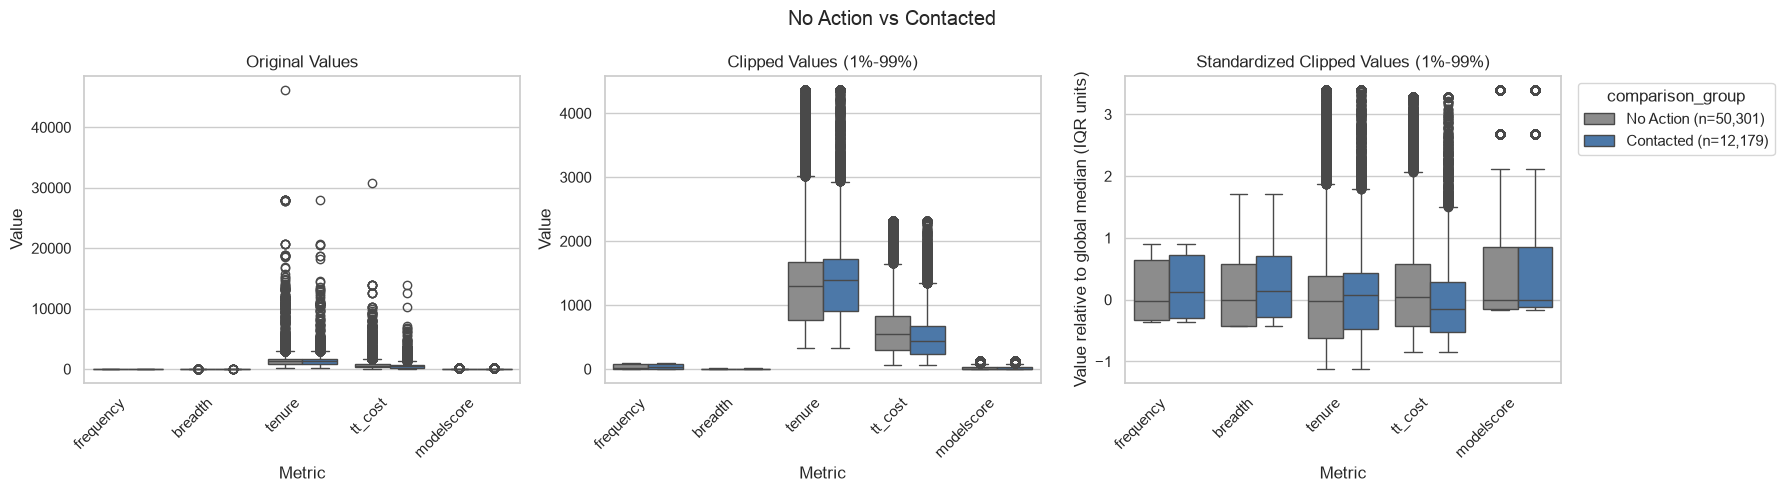

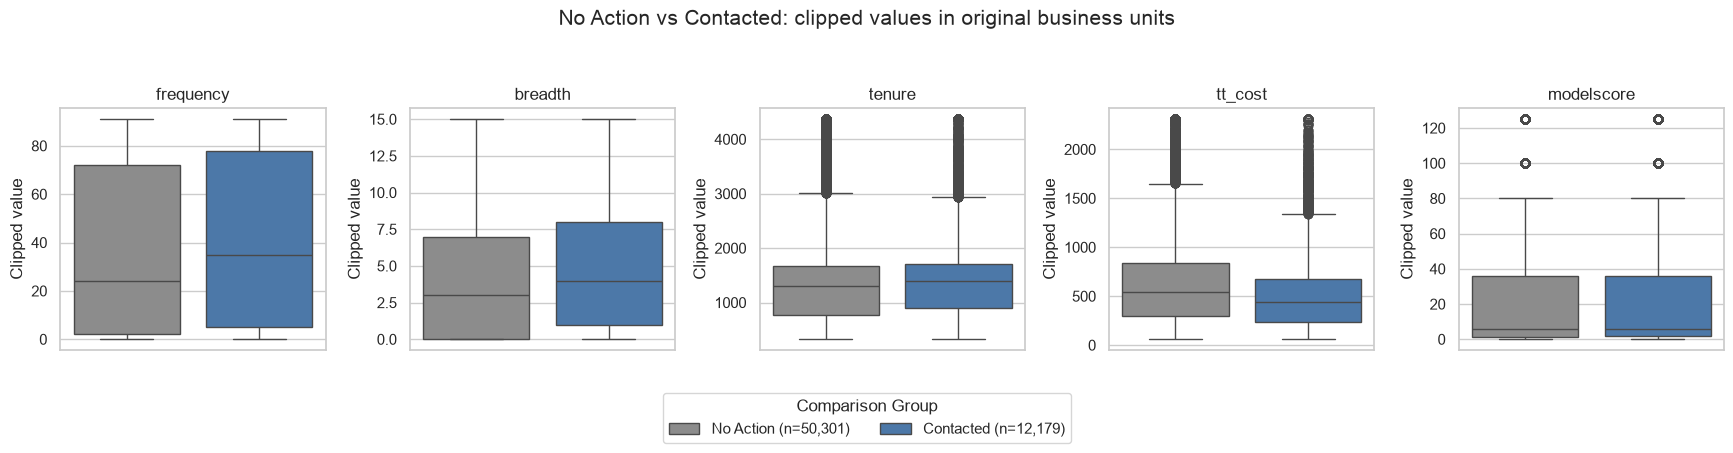

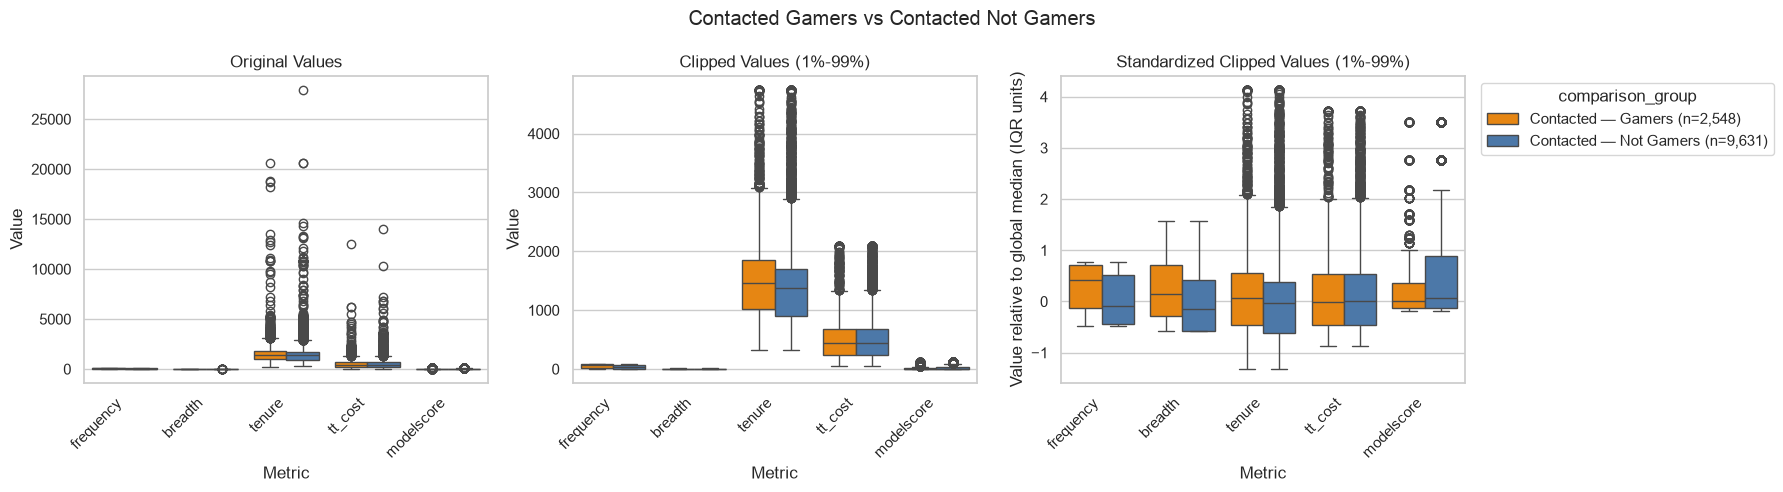

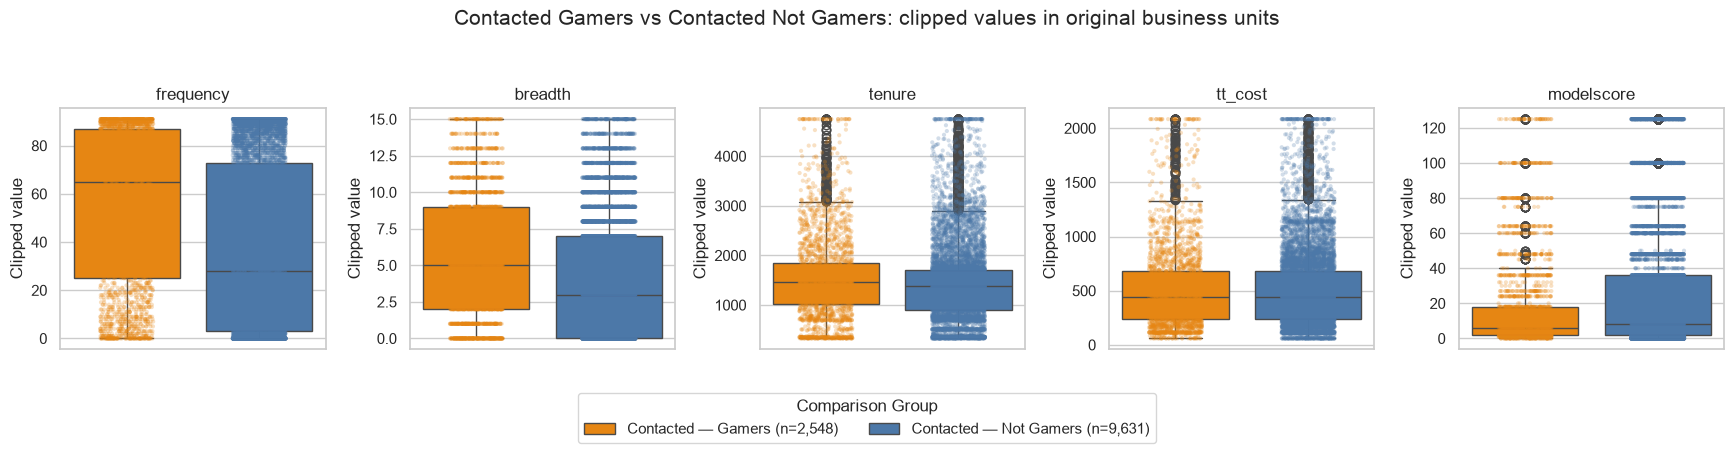

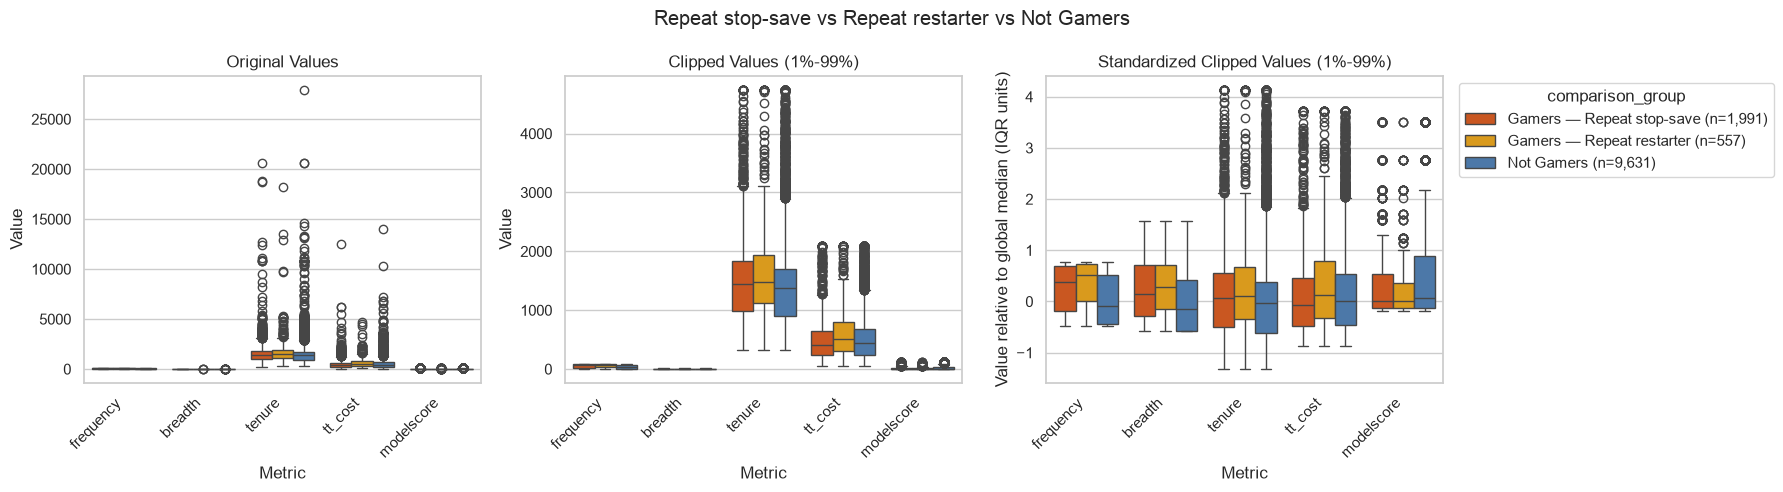

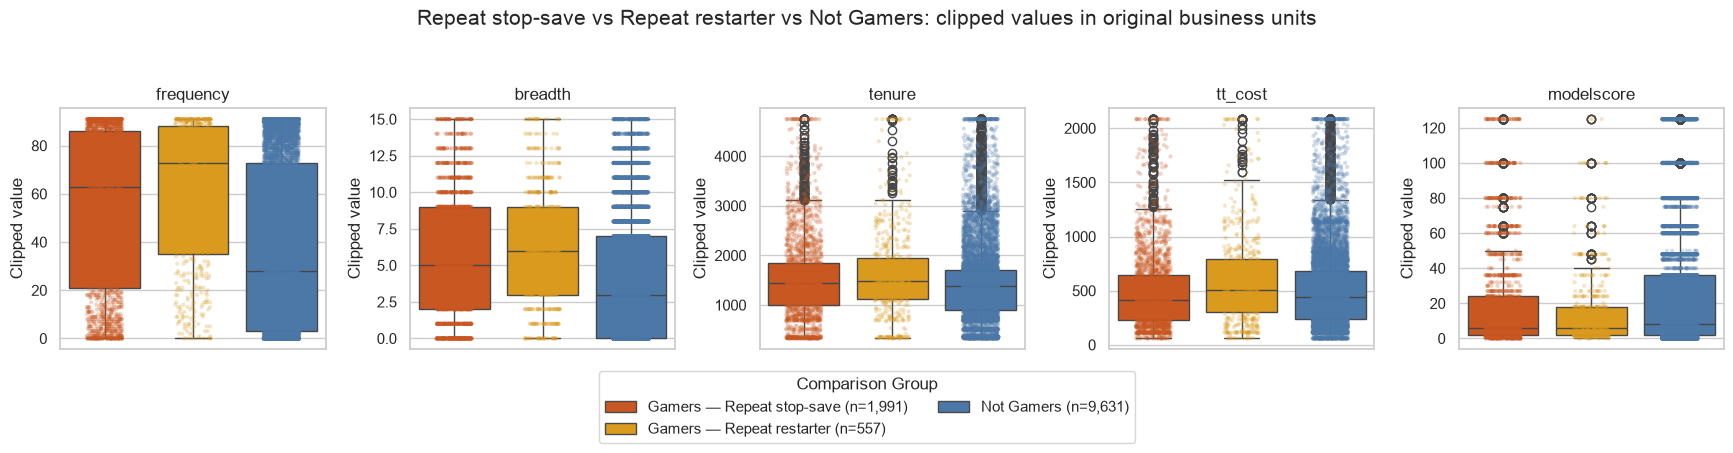

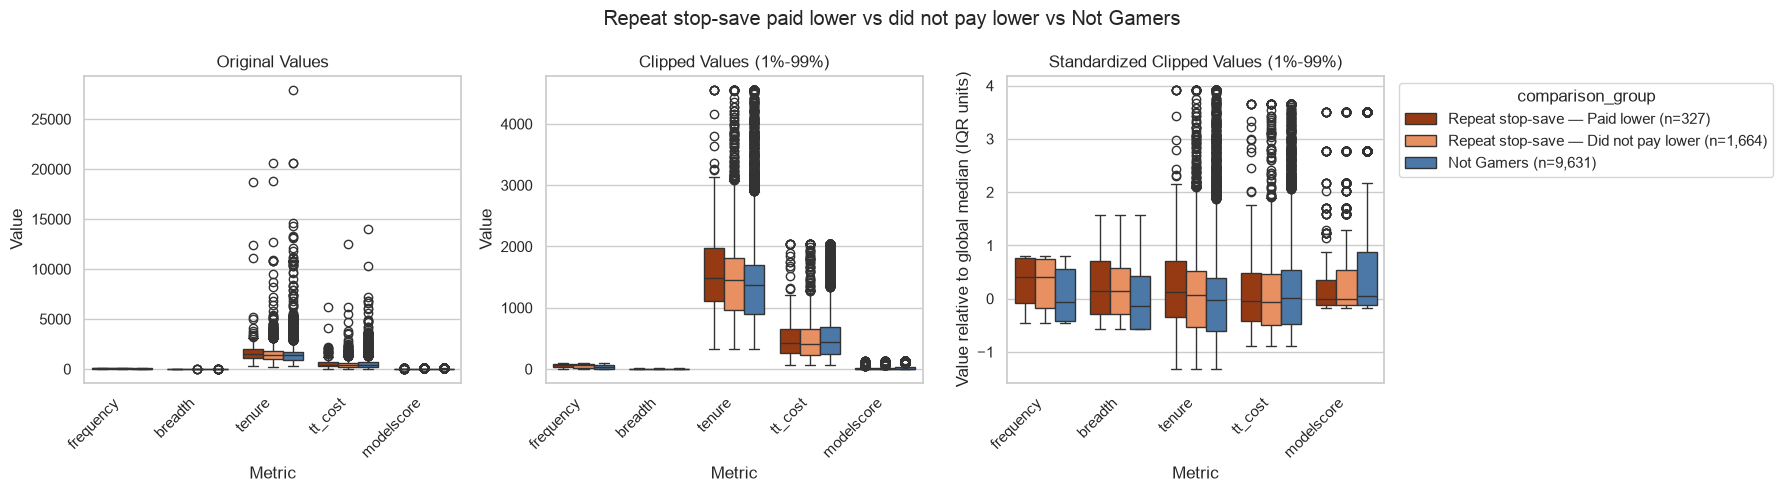

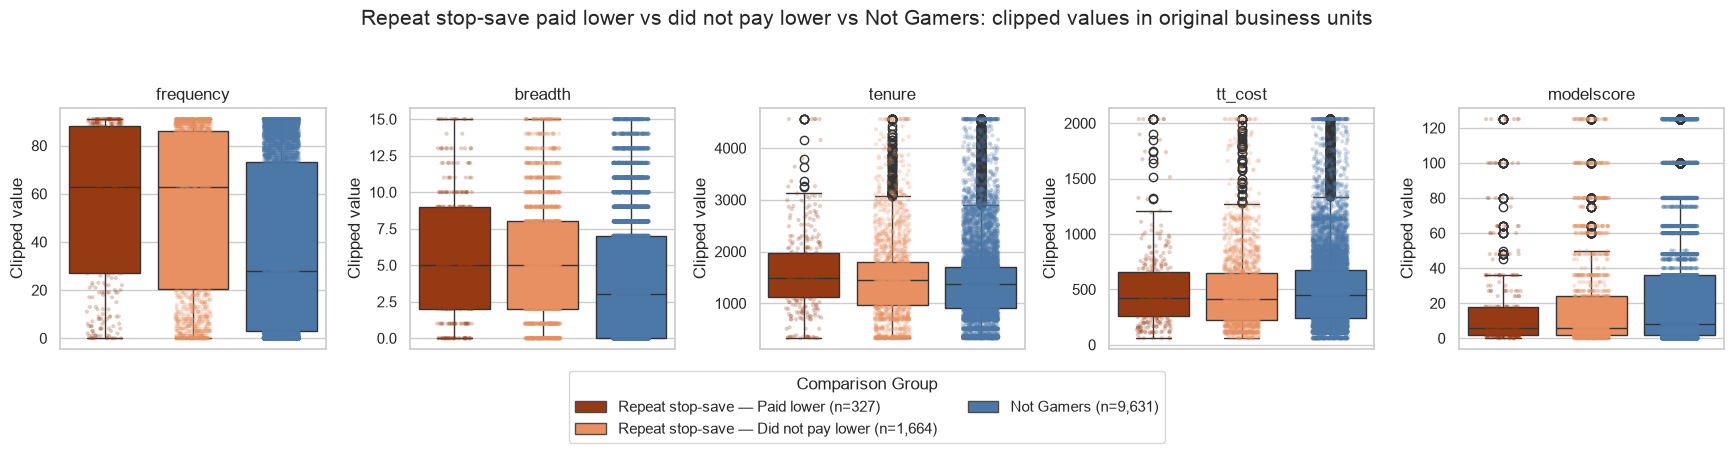

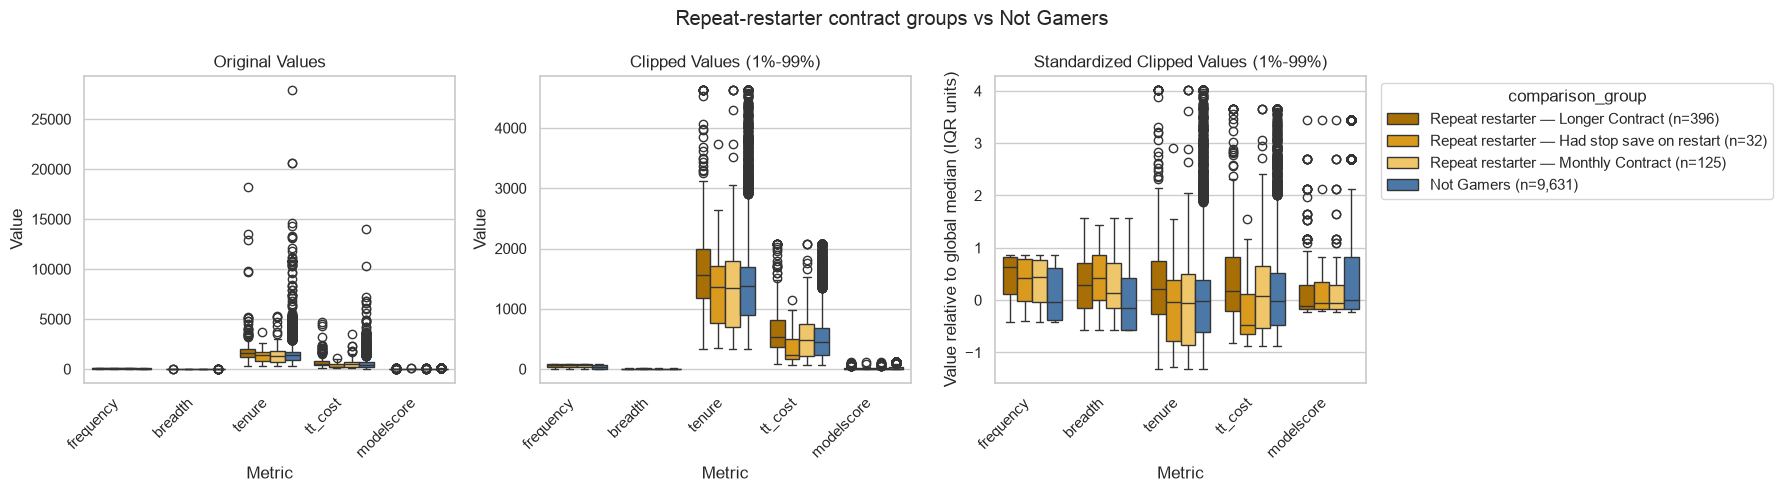

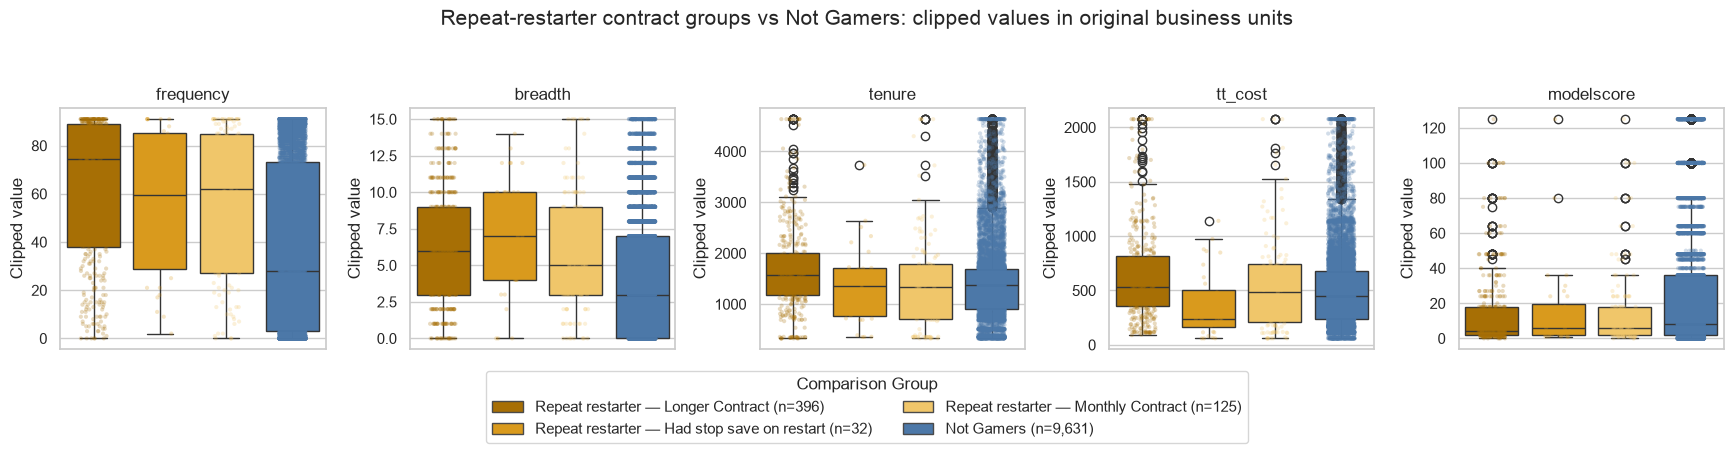

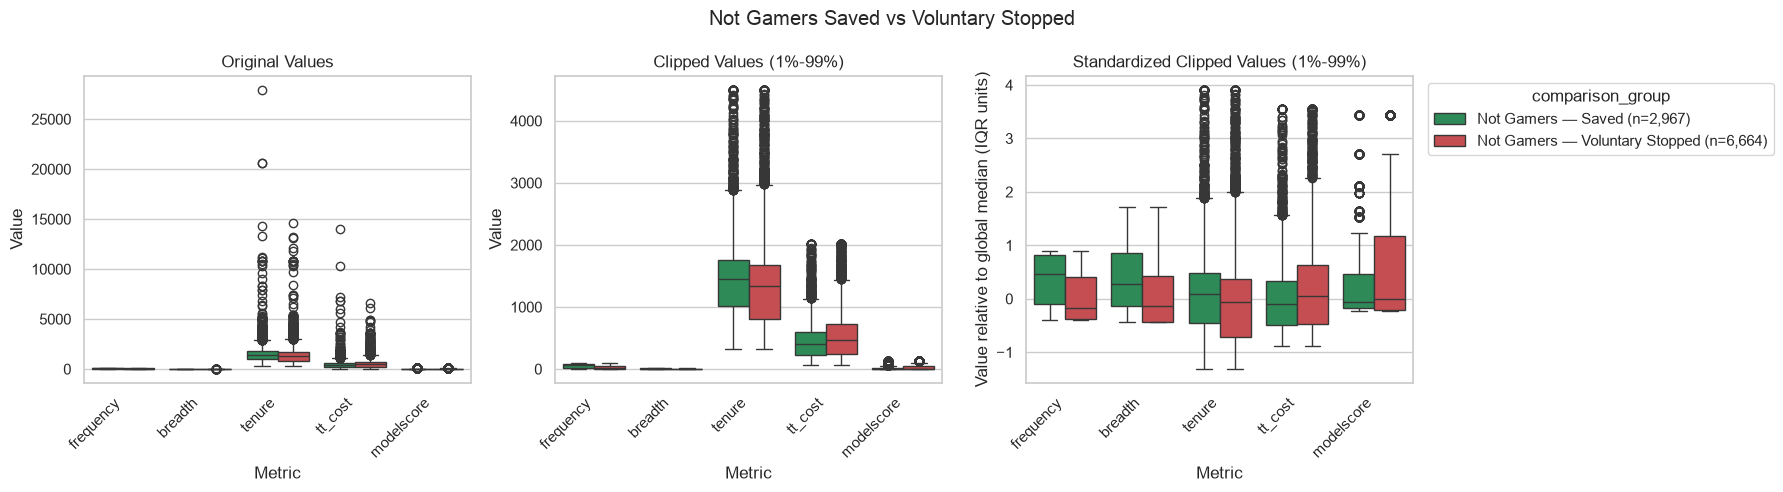

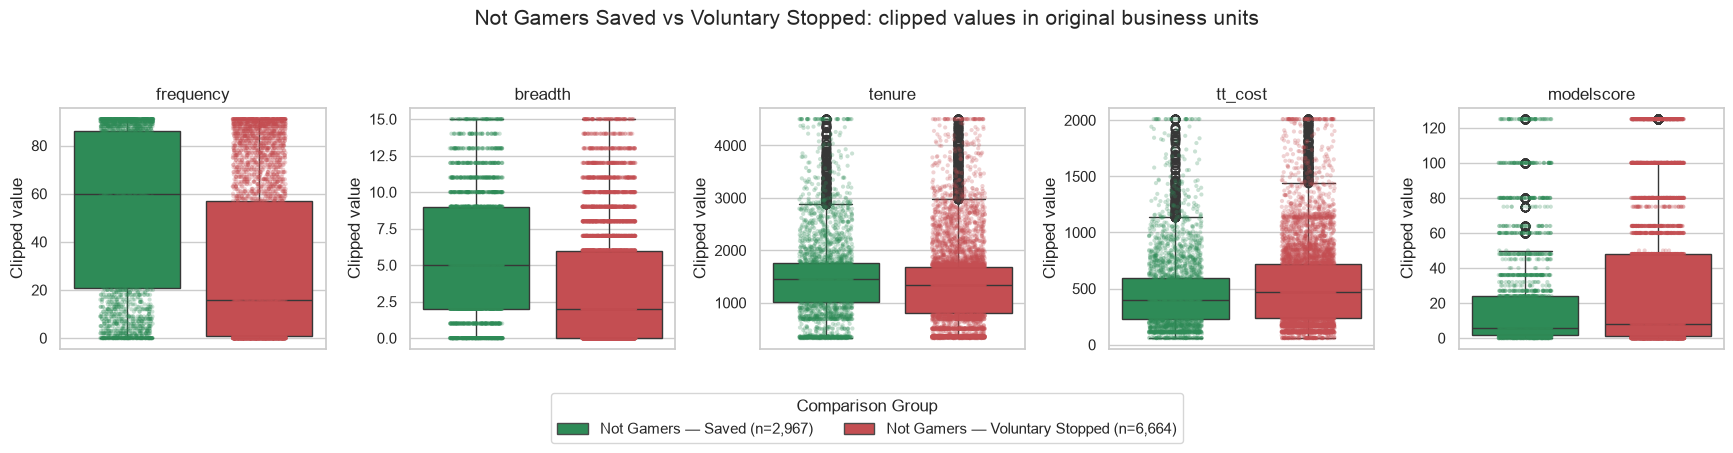

In [7]:
def compare_behavior_groups(comparison, groups, file_name, show_points):
    comparison_data = pd.concat(
        [
            df.loc[mask, [ID_COL, *BEHAVIOR_METRICS]].assign(comparison_group=label)
            for label, mask in groups
        ],
        ignore_index=True,
    )
    group_order = [label for label, _ in groups]
    summary = build_segment_summary(
        comparison_data, "comparison_group", BEHAVIOR_METRICS
    )
    summary.insert(0, "comparison", comparison)
    _ = plot_metric_boxplot_views(
        comparison_data,
        metrics=BEHAVIOR_METRICS,
        group_col="comparison_group",
        group_order=group_order,
        figsize=(18, 5),
        chart_title=comparison,
        chart_folder=POPULATION_COMPARISON_CHART_DIR,
        file_name=file_name,
        show=True,
        show_points=False,
    )
    _ = plot_group_clipped_boxplot_grid(
        comparison_data,
        metrics=BEHAVIOR_METRICS,
        group_col="comparison_group",
        group_order=group_order,
        panel_size=(3.5, 4.5),
        title=f"{comparison}: clipped values in original business units",
        chart_folder=POPULATION_COMPARISON_CHART_DIR,
        file_name=f"{Path(file_name).stem}_clipped_business_units.png",
        show=True,
        show_points=show_points,
    )
    return summary

comparison_specs = [
    (
        "No Action vs Contacted",
        [("No Action", ~contacted), ("Contacted", contacted)],
        "01_no_action_vs_contacted.png",
        False
    ),
    (
        "Contacted Gamers vs Contacted Not Gamers",
        [("Contacted — Gamers", gamers), ("Contacted — Not Gamers", not_gamers)],
        "02_gamers_vs_not_gamers.png",
        True
    ),
    (
        "Repeat stop-save vs Repeat restarter vs Not Gamers",
        [
            ("Gamers — Repeat stop-save", repeat_stop_saves),
            ("Gamers — Repeat restarter", repeat_restarters),
            ("Not Gamers", not_gamers),
        ],
        "03_repeat_stop_save_vs_restarter_vs_not_gamers.png",
        True
    ),
    (
        "Repeat stop-save paid lower vs did not pay lower vs Not Gamers",
        [
            ("Repeat stop-save — Paid lower", paid_lower_repeat_stop_saves),
            ("Repeat stop-save — Did not pay lower", repeat_stop_saves & ~paid_lower_repeat_stop_saves),
            ("Not Gamers", not_gamers),
        ],
        "04_paid_lower_vs_not_paid_lower_vs_not_gamers.png",
        True
    ),
    (
        "Repeat-restarter contract groups vs Not Gamers",
        [
            ("Repeat restarter — Longer Contract", restart_longer_contract),
            ("Repeat restarter — Had stop save on restart", restart_had_stop_save),
            ("Repeat restarter — Monthly Contract", restart_monthly_contract),
            ("Not Gamers", not_gamers),
        ],
        "05_restart_contract_groups_vs_not_gamers.png",
        True
    ),
    (
        "Not Gamers Saved vs Voluntary Stopped",
        [
            ("Not Gamers — Saved", not_gamers_saved),
            ("Not Gamers — Voluntary Stopped", not_gamers_stopped),
        ],
        "06_not_gamers_saved_vs_stopped.png",
        True
    ),
]

behavior_comparison_summary = pd.concat(
    [compare_behavior_groups(*spec) for spec in comparison_specs],
    ignore_index=True,
)
behavior_comparison_summary.to_csv(
    TABLE_DIR / "behavior_metric_population_comparisons.csv", index=False
)
# display(behavior_comparison_summary)

## 4. Not Gamer behavioral reference and Saved-versus-voluntary-Stopped contrasts

The `common behavioral reference` is fitted once on contacted Not Gamers. 

`Profiles` are calculated for Saved and voluntary-Stopped users within each combination of contact channel, contact timing, cohort, and source risk tier. 
- Only segments with at least `MIN_PROFILE_USERS` accounts (default 20) are retained. 
- For each metric within a segment, 
    - The profile score is calculated by clipping values to the 1st and 99th percentiles, centerring on the median, and dividing by the IQR of `common behavioral reference`. 
    - A profile score of `0` therefore matches the Not Gamer median; `+1` is one Not Gamer IQR above it and `-1` is one IQR below it.
    - The contrast is the Saved profile score minus the Stopped profile score for the same segment.
    - Positive contrast values mean the Saved median is higher. 
- `contrast_magnitude` of a segment is the Euclidean length of the five metric differences and ranks the segments with the largest overall behavioral separation.
    - captures both "one exceptionally large metric difference" and "several moderately large differences"
    - Larger magnitude: the typical Saved and Stopped users have more distinct behavioral profiles.

The treatment drill-down applies the same `common behavioral reference` to the highest-ranked segments and reports a contrast only when both outcomes meet `MIN_TREATMENT_USERS`(default 5). These are descriptive comparisons, not treatment-effect estimates.

In [8]:
baseline = df.loc[not_gamers].copy()
baseline[OUTCOME_COL] = baseline["churn_code"].map({0: "Saved", 1: "Stopped"})

behavior_reference = fit_behavior_reference(baseline, BEHAVIOR_METRICS)
reference_table = pd.DataFrame(
    {
        "p01": behavior_reference["lower_bounds"],
        "median": behavior_reference["centers"],
        "iqr": behavior_reference["spreads"],
        "p99": behavior_reference["upper_bounds"],
    }
).rename_axis("metric").reset_index()
reference_table.to_csv(TABLE_DIR / "primary_behavior_reference.csv", index=False)
display(reference_table)

,metric,p01,median,iqr,p99
0,frequency,0.00,28.00,70.00,91.00
1,breadth,0.00,3.00,7.00,15.00
2,tenure,327.00,"1,377.00",799.00,"4,502.88"
3,tt_cost,59.21,446.03,441.10,"2,009.85"
4,modelscore,0.00,8.00,34.00,125.00


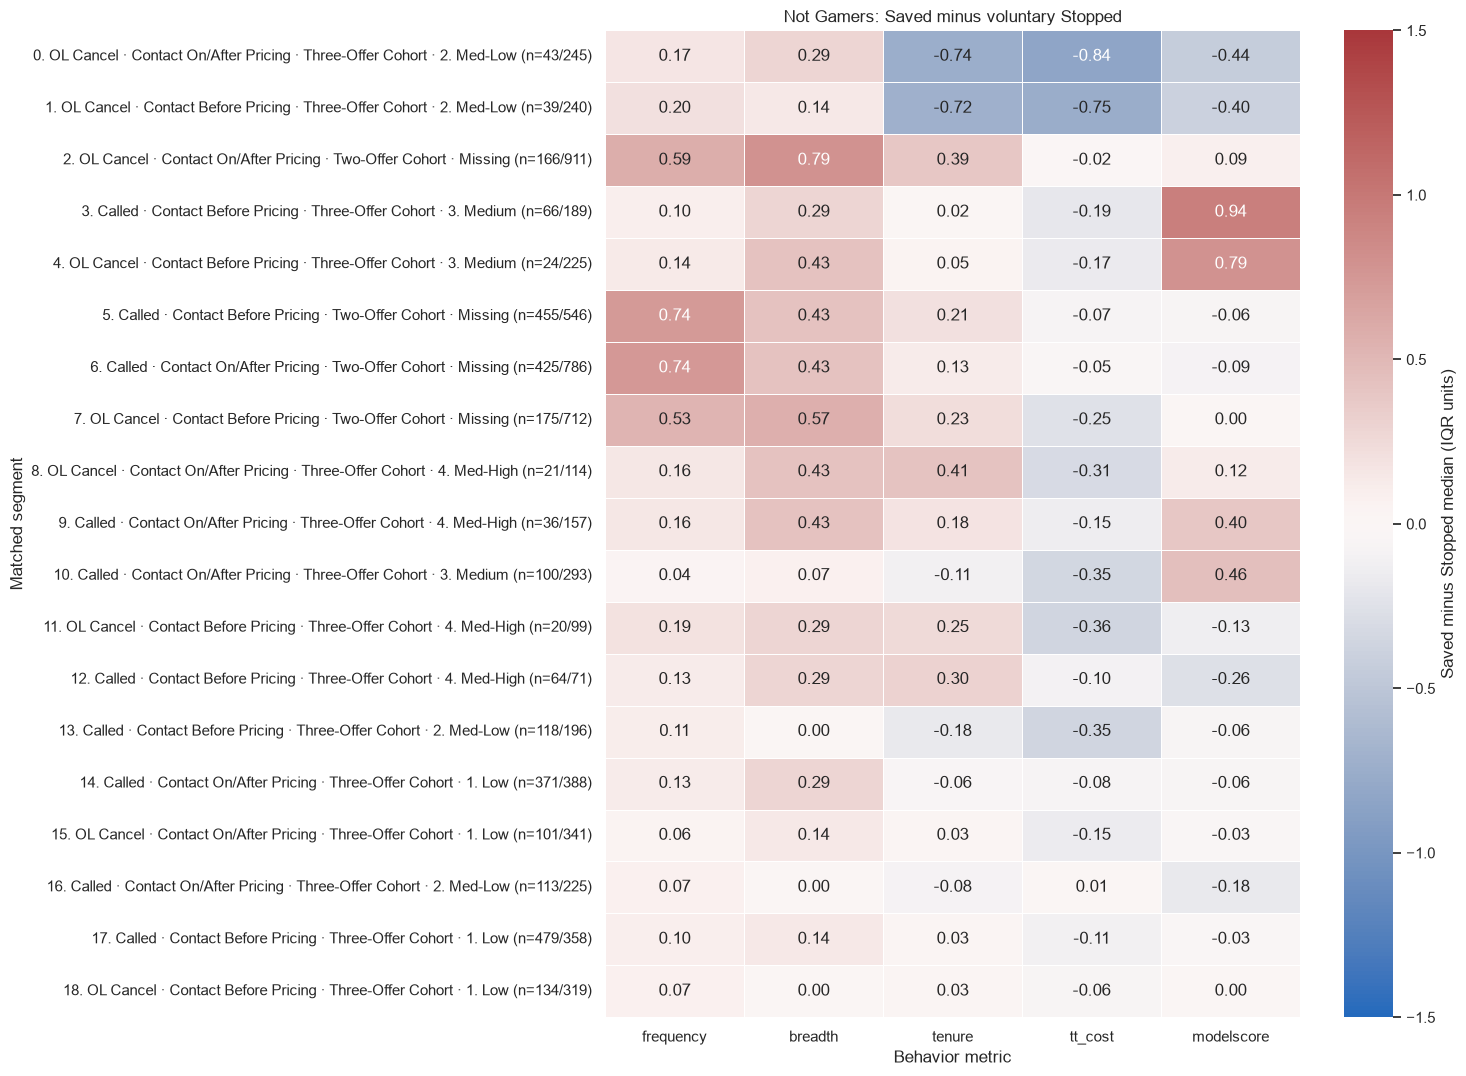

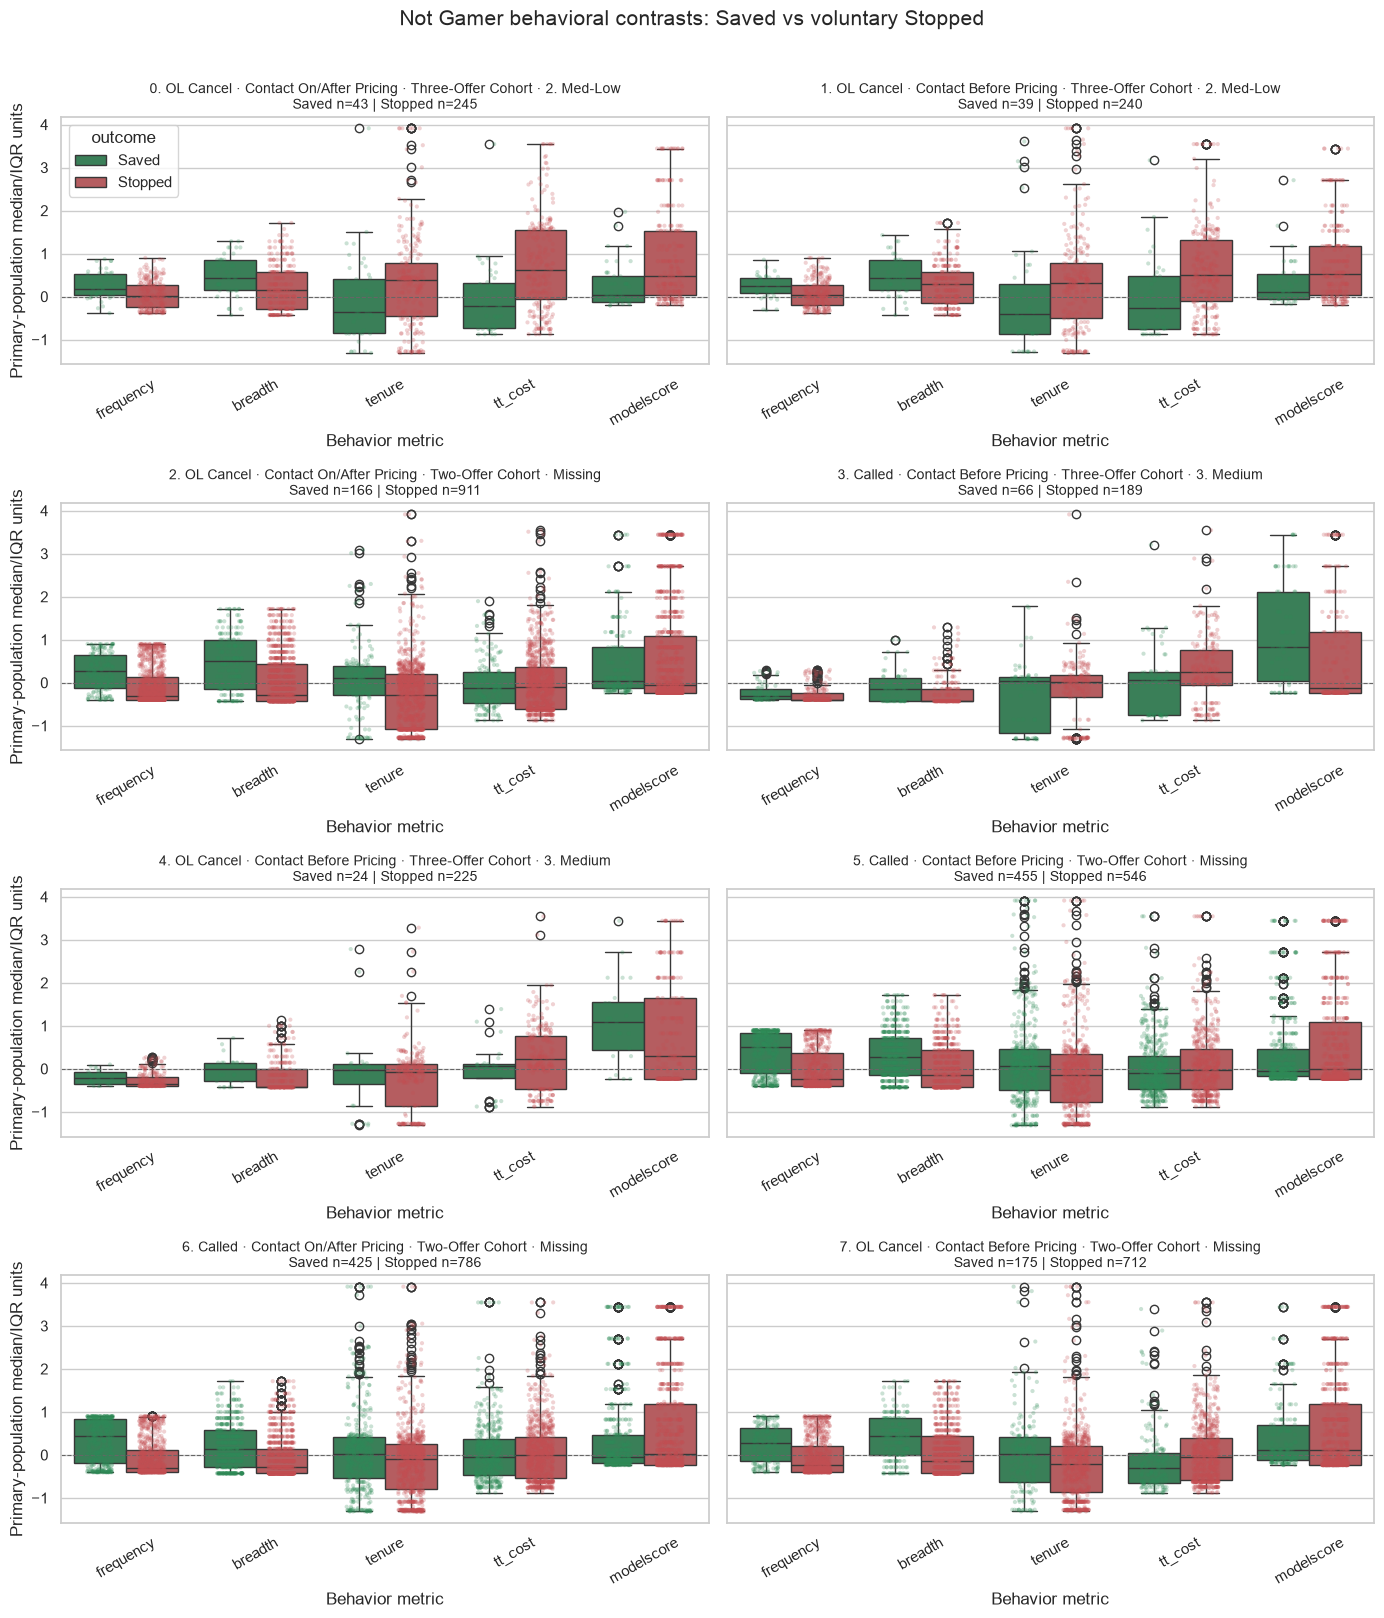

,segment_rank,contact_channels,contact_timing,cohort,src_risk_tier,segment_label,n__saved,n__stopped,median_saved__frequency,median_saved__breadth,median_saved__tenure,median_saved__tt_cost,median_saved__modelscore,median_stopped__frequency,median_stopped__breadth,median_stopped__tenure,median_stopped__tt_cost,median_stopped__modelscore,delta__frequency,delta__breadth,delta__tenure,delta__tt_cost,delta__modelscore,total_users,observed_saved_share,contrast_magnitude,dominant_metric,dominant_outcome
0,0,OL Cancel,Contact On/After Pricing,Three-Offer Cohort,2. Med-Low,OL Cancel · Contact On/After Pricing · Three-O...,43,245,41.00,6.00,"1,090.00",352.31,9.00,29.00,4.00,"1,684.00",721.07,24.00,0.17,0.29,-0.74,-0.84,-0.44,288,0.15,1.25,tt_cost,Stopped
1,1,OL Cancel,Contact Before Pricing,Three-Offer Cohort,2. Med-Low,OL Cancel · Contact Before Pricing · Three-Off...,39,240,45.00,6.00,"1,058.00",333.67,12.00,31.00,5.00,"1,633.50",666.33,25.50,0.20,0.14,-0.72,-0.75,-0.40,279,0.14,1.14,tt_cost,Stopped
2,2,OL Cancel,Contact On/After Pricing,Two-Offer Cohort,NaN,OL Cancel · Contact On/After Pricing · Two-Off...,166,911,47.00,6.50,"1,462.50",392.29,9.00,6.00,1.00,"1,151.50",400.12,6.00,0.59,0.79,0.39,-0.02,0.09,1077,0.15,1.06,breadth,Saved
3,3,Called,Contact Before Pricing,Three-Offer Cohort,3. Medium,Called · Contact Before Pricing · Three-Offer ...,66,189,7.00,2.00,"1,406.50",475.69,36.00,0.00,0.00,"1,389.00",558.75,4.00,0.10,0.29,0.02,-0.19,0.94,255,0.26,1.01,modelscore,Saved
4,4,OL Cancel,Contact Before Pricing,Three-Offer Cohort,3. Medium,OL Cancel · Contact Before Pricing · Three-Off...,24,225,12.50,3.00,"1,361.00",475.93,45.00,3.00,0.00,"1,319.00",549.12,18.00,0.14,0.43,0.05,-0.17,0.79,249,0.10,0.93,modelscore,Saved
5,5,Called,Contact Before Pricing,Two-Offer Cohort,NaN,Called · Contact Before Pricing · Two-Offer Co...,455,546,63.50,5.00,"1,425.50",398.22,6.00,12.00,2.00,"1,257.00",431.01,8.00,0.74,0.43,0.21,-0.07,-0.06,1001,0.45,0.88,frequency,Saved
6,6,Called,Contact On/After Pricing,Two-Offer Cohort,NaN,Called · Contact On/After Pricing · Two-Offer ...,425,786,58.00,4.00,"1,402.50",423.85,6.00,6.00,1.00,"1,300.00",444.22,9.00,0.74,0.43,0.13,-0.05,-0.09,1211,0.35,0.87,frequency,Saved
7,7,OL Cancel,Contact Before Pricing,Two-Offer Cohort,NaN,OL Cancel · Contact Before Pricing · Two-Offer...,175,712,48.00,6.00,"1,393.00",312.54,12.00,11.00,2.00,"1,209.00",421.74,12.00,0.53,0.57,0.23,-0.25,0.00,887,0.20,0.85,breadth,Saved


In [9]:
behavior_profiles = build_behavior_profiles(
    baseline,
    metrics=BEHAVIOR_METRICS,
    segment_fields=[OUTCOME_COL, *CORE_SEGMENT_FIELDS],
    reference=behavior_reference,
    min_n=MIN_PROFILE_USERS,
)
behavior_profiles.to_csv(TABLE_DIR / "not_gamer_behavior_profiles.csv", index=False)
_ = plot_profile_or_contrast_heatmap(
    behavior_profiles,
    metrics=BEHAVIOR_METRICS,
    score_type="profile",
    max_rows=30,
    title="Not Gamer behavior profiles relative to the Not Gamer reference",
    chart_folder=PROFILE_CHART_DIR,
    file_name="not_gamer_behavior_profiles.png",
    show=False,
)

outcome_contrasts = build_outcome_contrasts(
    behavior_profiles,
    metrics=BEHAVIOR_METRICS,
    segment_fields=CORE_SEGMENT_FIELDS,
)
outcome_contrasts.to_csv(TABLE_DIR / "not_gamer_saved_minus_stopped_contrasts.csv", index=False)
_ = plot_profile_or_contrast_heatmap(
    outcome_contrasts,
    metrics=BEHAVIOR_METRICS,
    score_type="contrast",
    max_rows=20,
    color_limit=1.5,
    title="Not Gamers: Saved minus voluntary Stopped",
    chart_folder=CONTRAST_CHART_DIR,
    file_name="not_gamer_saved_minus_stopped_contrasts.png",
    show=True,
)
_ = plot_behavior_contrasts_boxplots(
    baseline,
    outcome_contrasts,
    metrics=BEHAVIOR_METRICS,
    segment_fields=CORE_SEGMENT_FIELDS,
    reference=behavior_reference,
    top_n=TOP_CONTRASTS,
    chart_folder=CONTRAST_CHART_DIR,
    file_name="not_gamer_top_behavior_contrasts.png",
    title="Not Gamer behavioral contrasts: Saved vs voluntary Stopped",
    show=True,
)
display(outcome_contrasts.head(TOP_CONTRASTS))

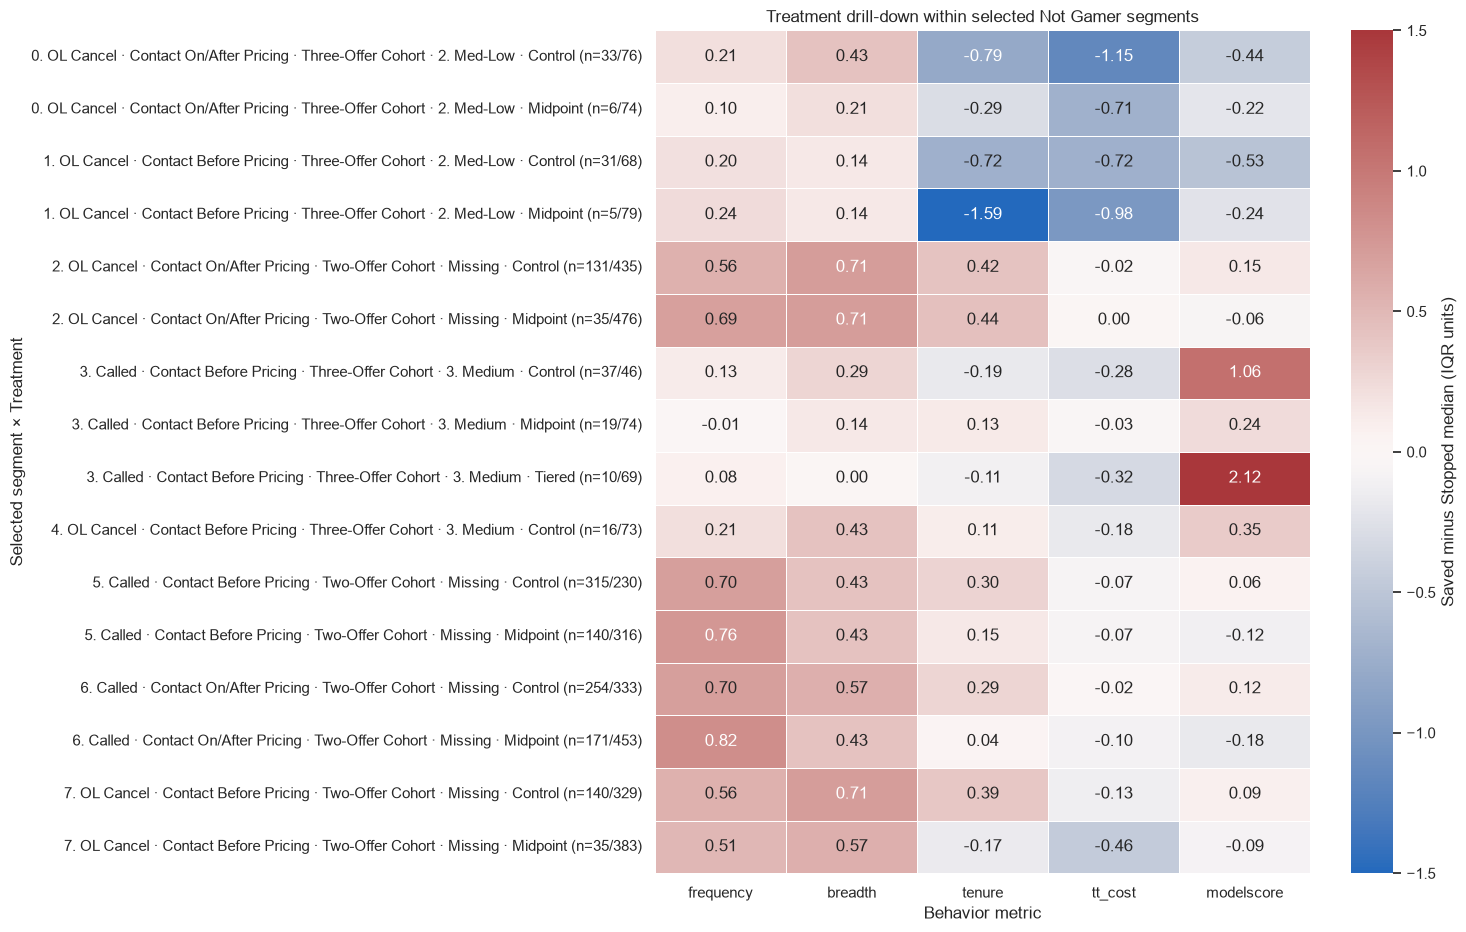

In [10]:
treatment_contrasts = build_treatment_contrasts(
    baseline,
    outcome_contrasts,
    metrics=BEHAVIOR_METRICS,
    segment_fields=CORE_SEGMENT_FIELDS,
    reference=behavior_reference,
    top_n=TOP_CONTRASTS,
    min_n=MIN_TREATMENT_USERS,
)
treatment_contrasts.to_csv(TABLE_DIR / "not_gamer_treatment_contrasts.csv", index=False)
supported_treatment = treatment_contrasts[treatment_contrasts["supported"]].copy()
_ = plot_profile_or_contrast_heatmap(
    supported_treatment,
    metrics=BEHAVIOR_METRICS,
    score_type="contrast",
    max_rows=30,
    color_limit=1.5,
    title="Treatment drill-down within selected Not Gamer segments",
    chart_folder=CONTRAST_CHART_DIR,
    file_name="not_gamer_treatment_contrasts.png",
    show=True,
)
# display(treatment_contrasts.head(12))

# # for idx, rank in enumerate([[0,2], [1,4], [3,5,6]]):        # v1
# for idx, rank in enumerate([[0,2], [3], [1,4,5,6,7]]):        # v2
#     _ = plot_behavior_contrasts_boxplots(
#         df_analysis,
#         support[support["segment_rank"].isin(rank)].copy(),
#         metrics=NUMERIC_FIELDS,
#         segment_fields=BASE_SEGMENT_FIELDS + ["Treatment"],
#         reference=behavior_reference,
#         top_n=TOP_CONTRASTS,
#         panel_size=(10, 4.5),
#         treatment_layout="metric_first",
#         chart_folder=CONTRAST_CHART_DIR,
#         title="Treatment drill-down within selected behavioral segments contrasts: Saved vs Stopped",
#         file_name=f"top_behavior_treatment_contrasts_{idx}.png",
#         show=True,
#     )

## v2 ref code. Business magnitude and uncertainty for selected segments drilled-down to Treatment

Only the fixed top pooled-treatment segments are expanded. Raw clipped boxplots retain business units; the detail table reuses the selected contrast counts and adds clipped medians, IQRs, and optional bootstrap intervals for median differences. Full-value grids are intentionally omitted.

In [11]:
# selected_segment_treatment_details = build_selected_segment_detail_table(
#     df_analysis,
#     treatment_contrasts,
#     metrics=NUMERIC_FIELDS,
#     segment_fields=BASE_SEGMENT_FIELDS+['Treatment'],
#     reference=behavior_reference,
#     top_n=30,
#     bootstrap_iterations=BOOTSTRAP_ITERATIONS,
#     confidence_level=BOOTSTRAP_CONFIDENCE_LEVEL,
# )
# selected_segment_treatment_details.to_csv(TABLE_DIR / "selected_segment_details.csv", index=False)
# # display(selected_segment_treatment_details.head(5))
# _ = plot_selected_segment_clipped_boxplot_grid(
#     df_analysis,
#     treatment_contrasts[treatment_contrasts["supported"]].copy(),
#     metrics=NUMERIC_FIELDS,
#     segment_fields=BASE_SEGMENT_FIELDS+['Treatment'],
#     reference=behavior_reference,
#     top_n=30,
#     chart_folder=CONTRAST_CHART_DIR,
#     title="Treatment drill-down Raw clipped values for business magnitude: Saved vs Stopped",
#     file_name="treatment_selected_segments_raw_clipped.png",
#     show=True,
# )

## 5. Categorical behavior dimensions

Each dimension is shown as the category composition within each comparison group. For example, the `favor_platforms` panel shows what percentage of Saved users favor the native app, desktop, or another platform alongside the same percentages for voluntary-Stopped users. Each group's bars sum to 100% within a dimension, so concentrations are visible directly rather than being encoded as a signed share difference.

Dimensions are analyzed separately to avoid a sparse Cartesian segmentation. Categories representing at least 1% of the combined comparison population are retained, up to nine categories, and the remainder are combined as `Other`; the most common categories are used as a fallback. The exported table retains the displayed counts, within-group percentages, and category order used by the charts.

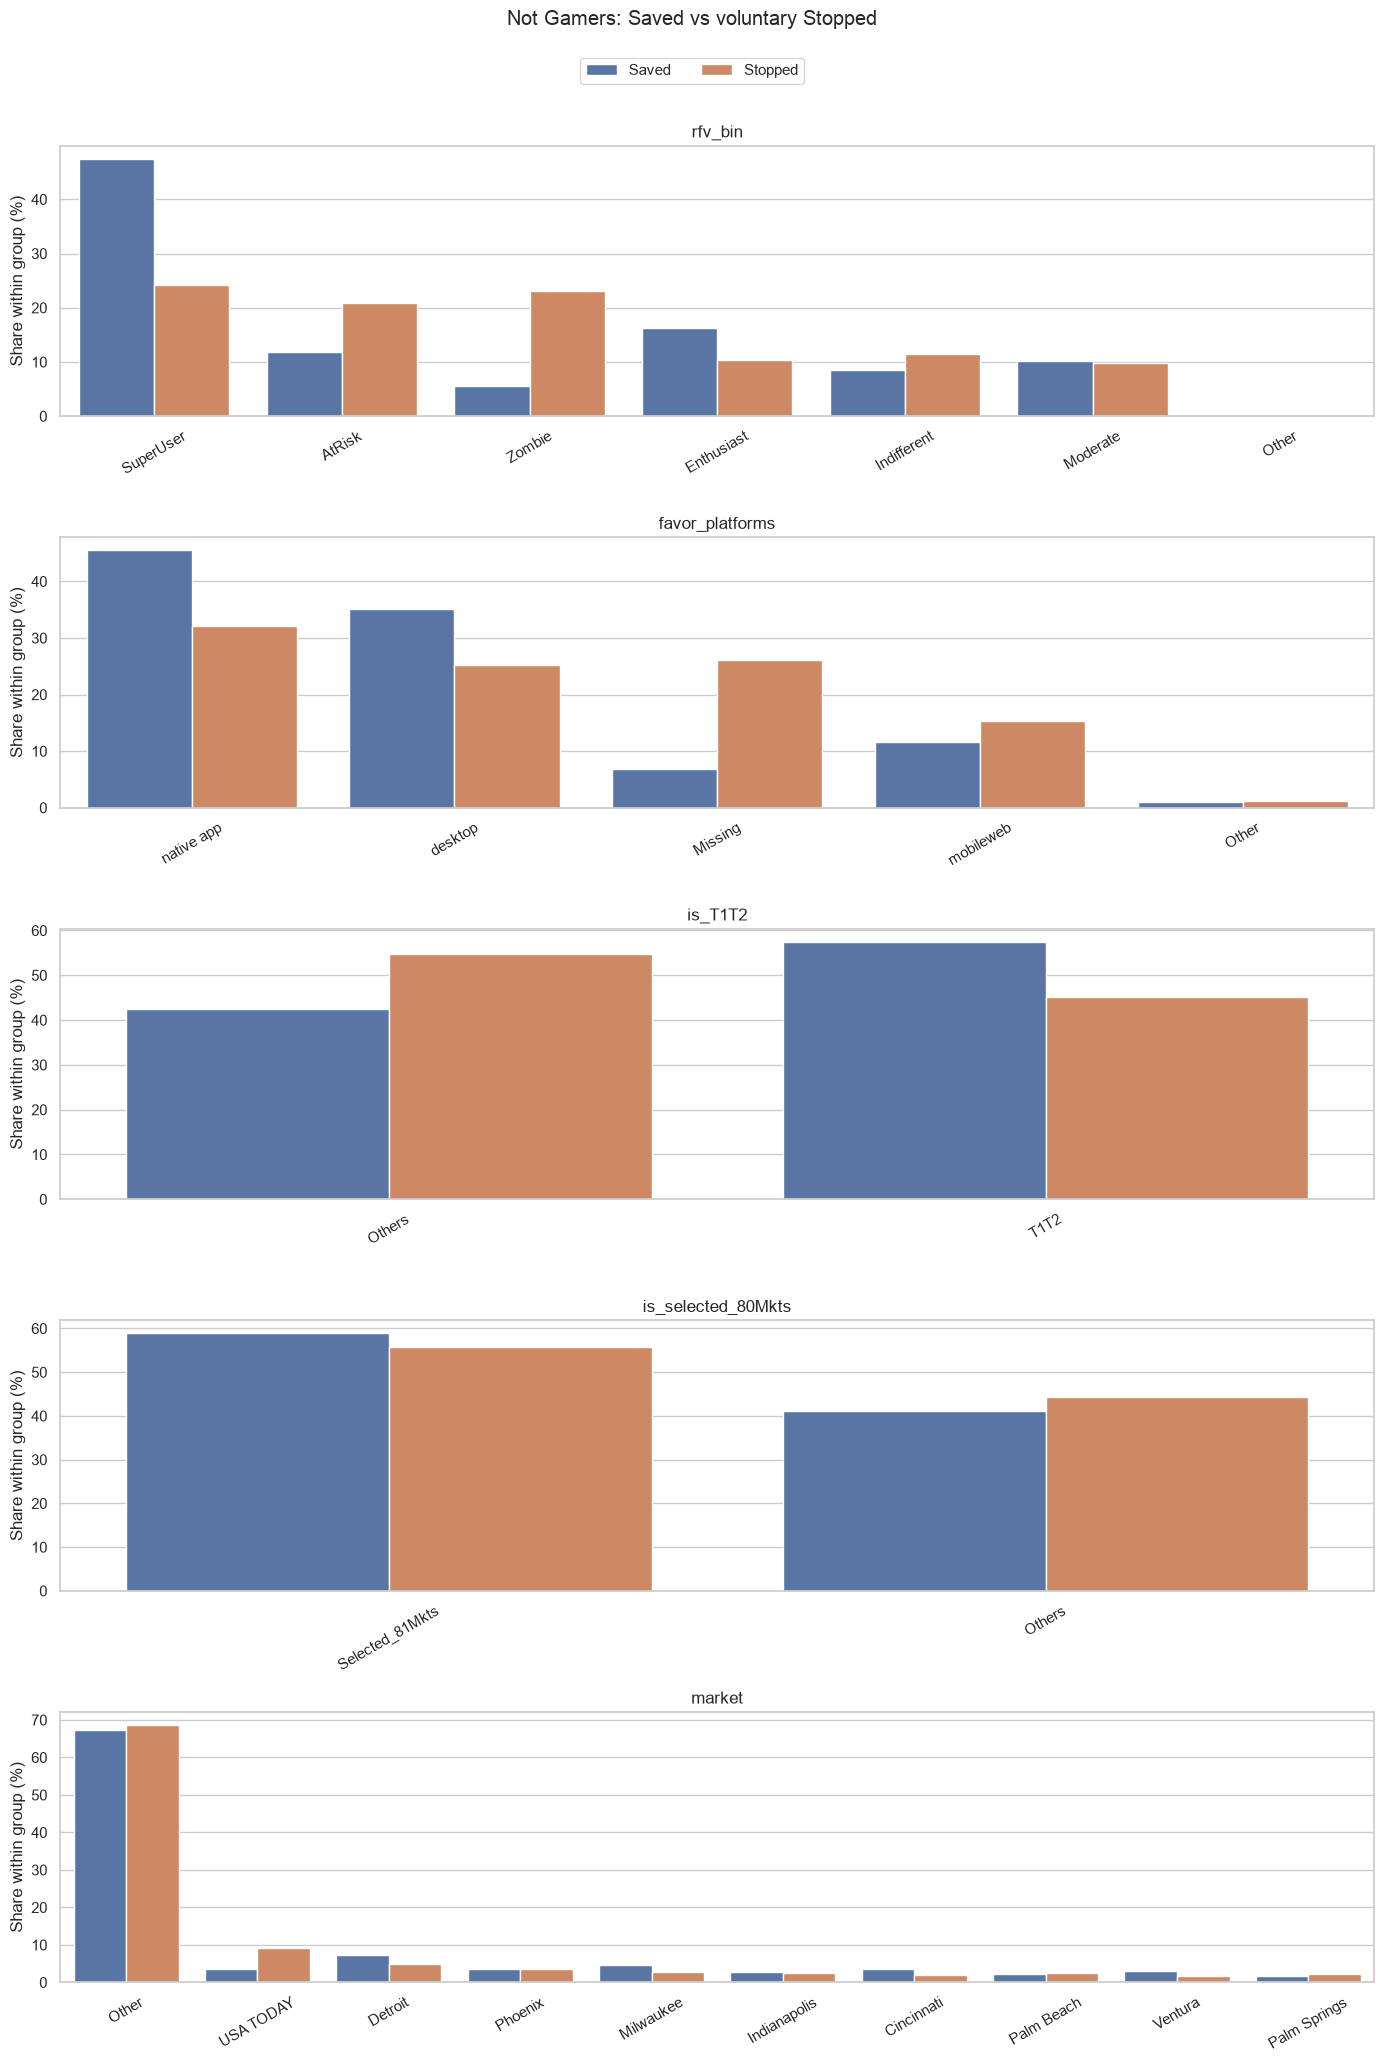

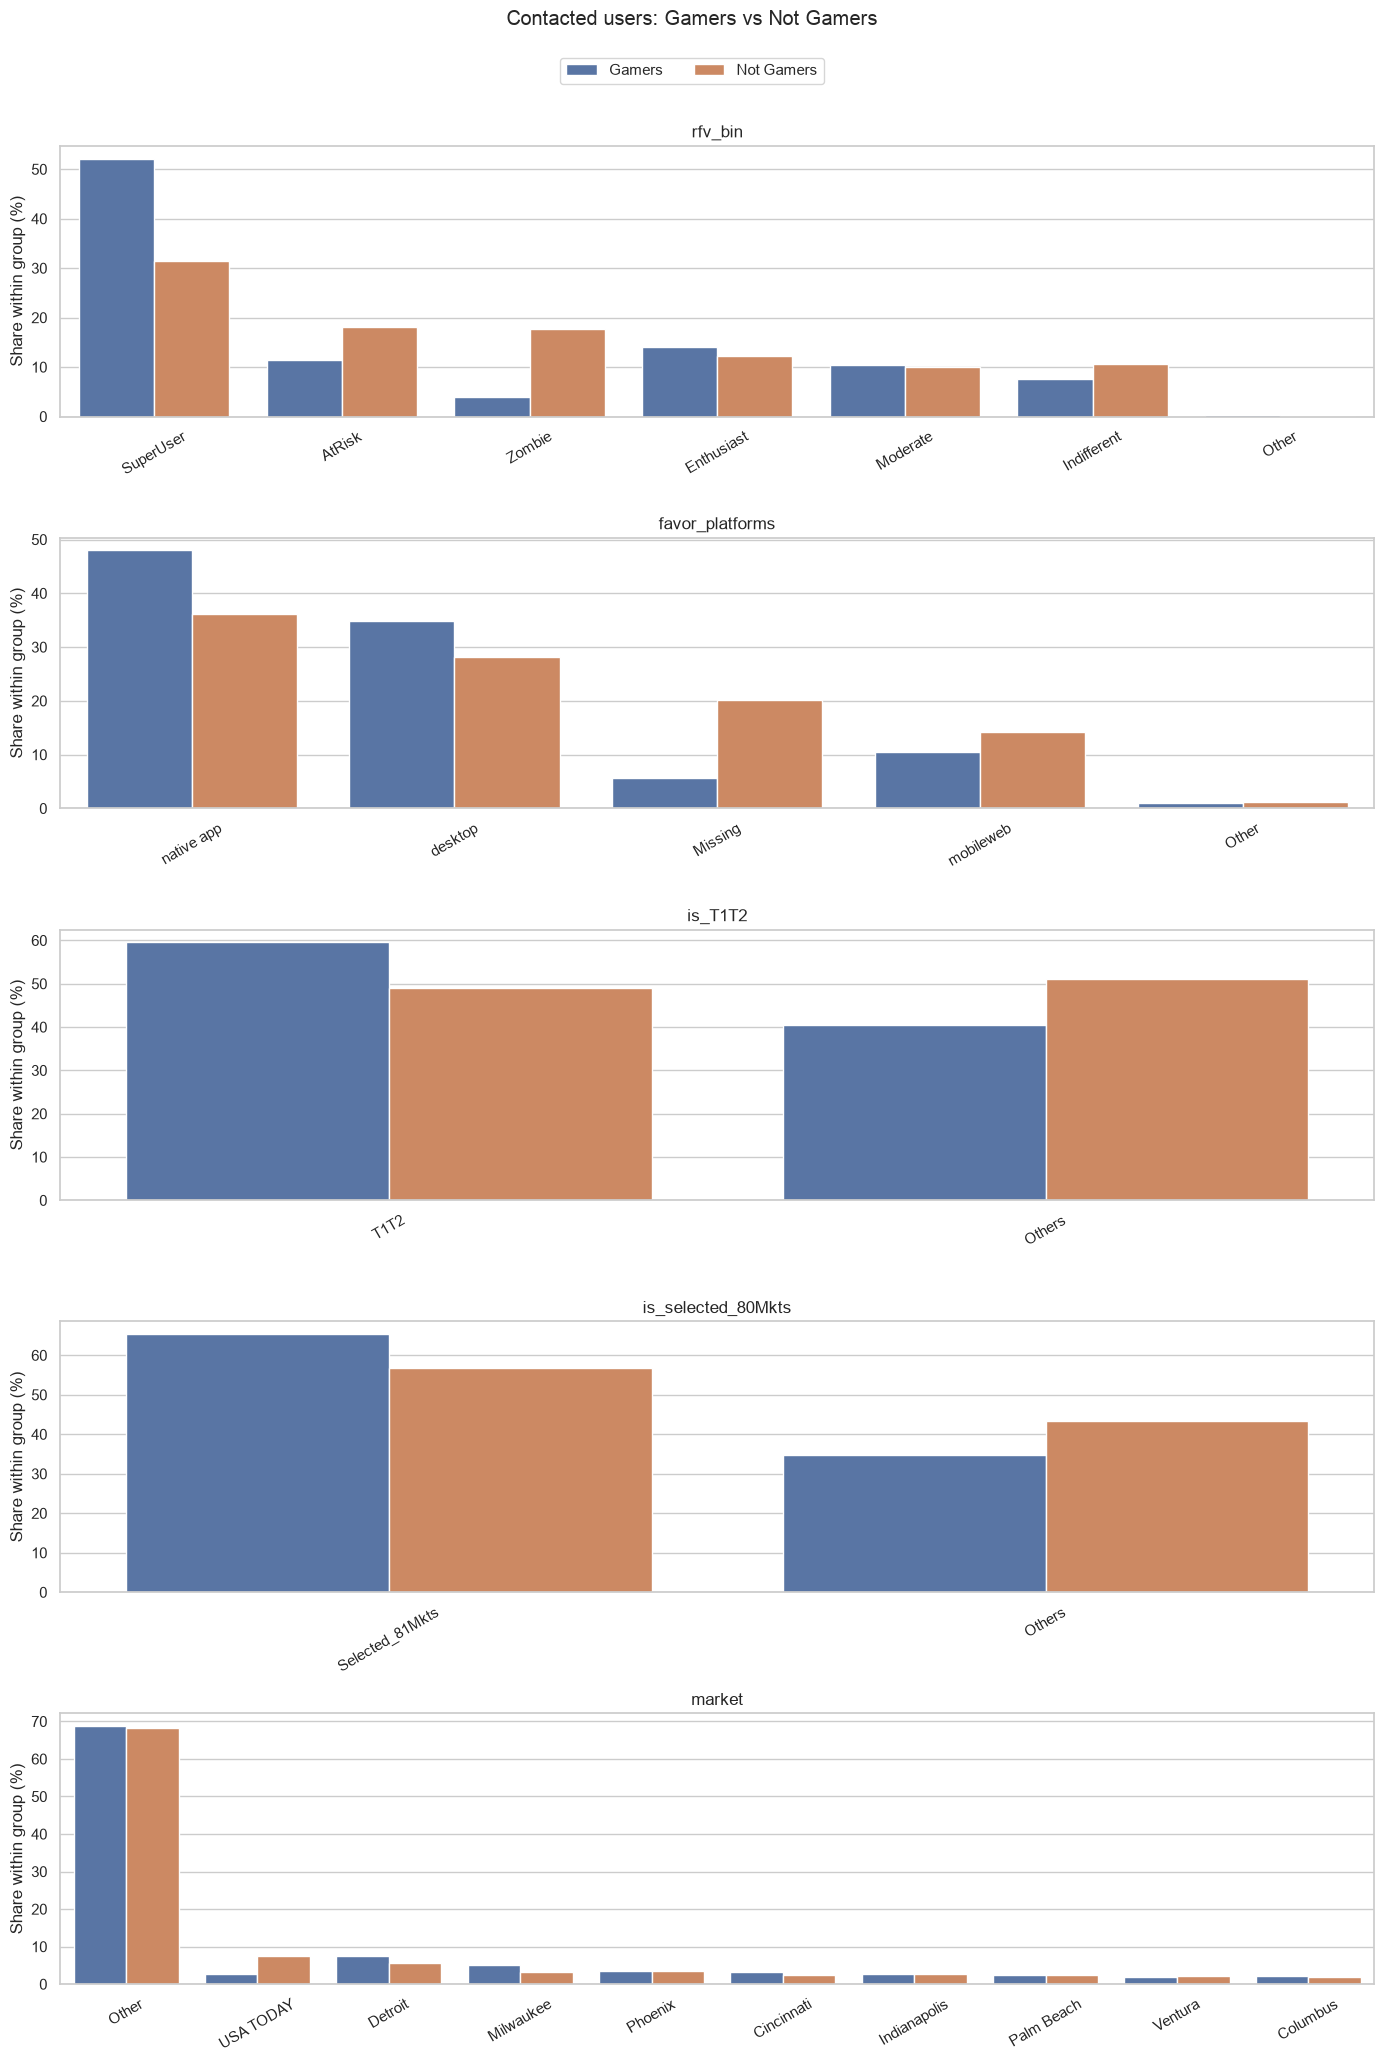

,comparison,dimension,comparison_group,dimension_value,category_order,accounts,within_group_share_pct
14,Not Gamers: Saved vs voluntary Stopped,favor_platforms,Saved,native app,0,1351,45.53
15,Not Gamers: Saved vs voluntary Stopped,favor_platforms,Saved,desktop,1,1040,35.05
16,Not Gamers: Saved vs voluntary Stopped,favor_platforms,Saved,Missing,2,202,6.81
17,Not Gamers: Saved vs voluntary Stopped,favor_platforms,Saved,mobileweb,3,344,11.59
18,Not Gamers: Saved vs voluntary Stopped,favor_platforms,Saved,Other,4,30,1.01
19,Not Gamers: Saved vs voluntary Stopped,favor_platforms,Stopped,native app,0,2135,32.04
20,Not Gamers: Saved vs voluntary Stopped,favor_platforms,Stopped,desktop,1,1680,25.21
21,Not Gamers: Saved vs voluntary Stopped,favor_platforms,Stopped,Missing,2,1740,26.11
22,Not Gamers: Saved vs voluntary Stopped,favor_platforms,Stopped,mobileweb,3,1027,15.41
23,Not Gamers: Saved vs voluntary Stopped,favor_platforms,Stopped,Other,4,82,1.23


In [12]:
def build_categorical_composition(
    data, group_col, group_order, dimensions, comparison, max_categories=10,
    min_category_share_pct=1,
):
    records = []
    selected = data.loc[data[group_col].isin(group_order)].copy()
    for dimension in dimensions:
        values = selected[dimension].astype("string").fillna("Missing")
        category_counts = values.value_counts()
        category_shares = category_counts.div(len(values)).mul(100)
        retained = category_shares.loc[
            category_shares.ge(min_category_share_pct)
        ].head(max_categories - 1).index
        if len(retained) < min(2, len(category_counts)):
            retained = category_counts.head(max_categories - 1).index
        if len(retained) < len(category_counts):
            values = values.where(values.isin(retained), "Other")

        counts = pd.crosstab(selected[group_col], values).reindex(
            index=group_order, fill_value=0
        )
        category_order = counts.sum(axis=0).sort_values(ascending=False).index.tolist()
        shares = counts.div(counts.sum(axis=1), axis=0).mul(100)
        for group in group_order:
            for order, value in enumerate(category_order):
                records.append(
                    {
                        "comparison": comparison,
                        "dimension": dimension,
                        "comparison_group": group,
                        "dimension_value": str(value),
                        "category_order": order,
                        "accounts": int(counts.loc[group, value]),
                        "within_group_share_pct": shares.loc[group, value],
                    }
                )
    return pd.DataFrame.from_records(records)


def plot_categorical_composition(data, comparison, group_order, file_name):
    plot_data = data.loc[data["comparison"].eq(comparison)].copy()
    fig, axes = plt.subplots(
        len(CATEGORICAL_DIMENSIONS), 1, figsize=(14, 4 * len(CATEGORICAL_DIMENSIONS))
    )
    legend_handles = legend_labels = None
    for ax, dimension in zip(axes, CATEGORICAL_DIMENSIONS):
        dimension_data = plot_data.loc[plot_data["dimension"].eq(dimension)].copy()
        category_order = (
            dimension_data[["dimension_value", "category_order"]]
            .drop_duplicates()
            .sort_values("category_order")["dimension_value"]
            .tolist()
        )
        sns.barplot(
            data=dimension_data,
            x="dimension_value",
            y="within_group_share_pct",
            hue="comparison_group",
            order=category_order,
            hue_order=group_order,
            ax=ax,
        )
        ax.set_title(dimension)
        ax.set_xlabel("")
        ax.set_ylabel("Share within group (%)")
        ax.tick_params(axis="x", rotation=30)
        legend_handles, legend_labels = ax.get_legend_handles_labels()
        ax.get_legend().remove()
    fig.legend(
        legend_handles, legend_labels, loc="upper center", ncol=len(group_order),
        bbox_to_anchor=(0.5, 1.01),
    )
    fig.suptitle(comparison, y=1.03)
    fig.tight_layout()
    fig.savefig(CONTRAST_CHART_DIR / file_name, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


categorical_outcome = build_categorical_composition(
    baseline, OUTCOME_COL, ["Saved", "Stopped"], CATEGORICAL_DIMENSIONS,
    comparison="Not Gamers: Saved vs voluntary Stopped",
)
contacted_users = df.loc[contacted].copy()
contacted_users["comparison_group"] = np.where(
    gamers.loc[contacted], "Gamers", "Not Gamers"
)
categorical_gamer = build_categorical_composition(
    contacted_users, "comparison_group", ["Gamers", "Not Gamers"],
    CATEGORICAL_DIMENSIONS, comparison="Contacted users: Gamers vs Not Gamers",
)
categorical_composition = pd.concat(
    [categorical_outcome, categorical_gamer], ignore_index=True
)
categorical_composition.to_csv(
    TABLE_DIR / "categorical_group_composition.csv", index=False
)
plot_categorical_composition(
    categorical_composition, "Not Gamers: Saved vs voluntary Stopped",
    ["Saved", "Stopped"], "categorical_saved_vs_stopped.png",
)
plot_categorical_composition(
    categorical_composition, "Contacted users: Gamers vs Not Gamers",
    ["Gamers", "Not Gamers"], "categorical_gamers_vs_not_gamers.png",
)
display(
    categorical_outcome.loc[categorical_outcome["dimension"].eq("favor_platforms")]
)

## 6. Repeat-restarter revenue scenario

Actual paid-invoice value is compared with the P3 expected-fixed scenario by restart type, contract type, and restart stop-save status. Positive scenario difference means expected fixed revenue exceeds actual paid-invoice value. This remains a scenario calculation, not a causal estimate.

,dimension,dimension_value,restarters,actual_paid_invoice_value,expected_fixed_revenue,median_actual_paid_invoice_value,median_expected_fixed_revenue,scenario_difference,actual_to_expected_ratio
0,overall,All repeat restarters,557,47742.150000000,11121.750000000,99.00,14.99,-36620.400000000,4.29
1,restart_type,repeat restart via intro,451,40449.250000000,8374.480000000,99.00,14.99,-32074.770000000,4.83
2,restart_type,repeat restart via winback,106,7292.900000000,2747.270000000,99.00,17.48,-4545.630000000,2.65
3,restart_contract_type,Longer Contract,396,44737.000000000,5886.020000000,119.00,14.99,-38850.980000000,7.60
4,restart_contract_type,Monthly Contract,157,3005.150000000,5235.730000000,15.99,29.98,2230.580000000,0.57
5,restart_contract_type,No Payment,4,0E-9,0E-9,0.00,0.00,0E-9,NaN
6,restart_stop_save,False,525,47337.870000000,10050.270000000,99.00,14.99,-37287.600000000,4.71
7,restart_stop_save,True,32,404.280000000,1071.480000000,10.98,27.96,667.200000000,0.38


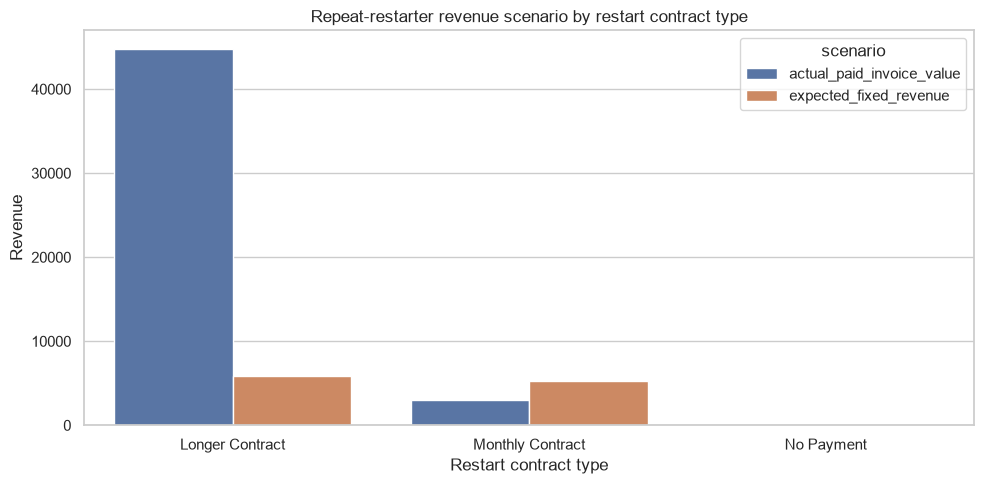

In [13]:
def summarize_restart_revenue(data, dimension, dimension_label):
    grouped = (
        data.groupby(dimension, dropna=False)
        .agg(
            restarters=("id_subscrip", "nunique"),
            actual_paid_invoice_value=("actual_paid_invoice_value", "sum"),
            expected_fixed_revenue=("expected_fixed_revenue", "sum"),
            median_actual_paid_invoice_value=("actual_paid_invoice_value", "median"),
            median_expected_fixed_revenue=("expected_fixed_revenue", "median"),
        )
        .reset_index()
        .rename(columns={dimension: "dimension_value"})
    )
    grouped.insert(0, "dimension", dimension_label)
    grouped["scenario_difference"] = (
        grouped["expected_fixed_revenue"] - grouped["actual_paid_invoice_value"]
    )
    grouped["actual_to_expected_ratio"] = np.nan
    nonzero_expected = grouped["expected_fixed_revenue"].ne(0)
    grouped.loc[nonzero_expected, "actual_to_expected_ratio"] = (
        grouped.loc[nonzero_expected, "actual_paid_invoice_value"].astype(float)
        / grouped.loc[nonzero_expected, "expected_fixed_revenue"].astype(float)
    )
    return grouped

restarters = df.loc[repeat_restarters].copy()
restarters["overall"] = "All repeat restarters"
revenue_summary = pd.concat(
    [
        summarize_restart_revenue(restarters, "overall", "overall"),
        summarize_restart_revenue(restarters, "Repeat_Restarts", "restart_type"),
        summarize_restart_revenue(restarters, "service_period_type", "restart_contract_type"),
        summarize_restart_revenue(restarters, "had_restart_stop_save", "restart_stop_save"),
    ],
    ignore_index=True,
)
revenue_summary.to_csv(TABLE_DIR / "repeat_restarter_revenue_summary.csv", index=False)
display(revenue_summary)

contract_revenue = revenue_summary[revenue_summary["dimension"].eq("restart_contract_type")].copy()
contract_plot = contract_revenue.melt(
    id_vars="dimension_value",
    value_vars=["actual_paid_invoice_value", "expected_fixed_revenue"],
    var_name="scenario",
    value_name="revenue",
)
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=contract_plot, x="dimension_value", y="revenue", hue="scenario", ax=ax)
ax.set_title("Repeat-restarter revenue scenario by restart contract type")
ax.set_xlabel("Restart contract type")
ax.set_ylabel("Revenue")
fig.tight_layout()
fig.savefig(REVENUE_CHART_DIR / "revenue_by_restart_contract_type.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

## 7. Interpretation boundaries

- The Not Gamer reference is the fixed scale for the detailed Saved-versus-Stopped profiles and contrasts in section 4. Population-comparison charts in section 3 use their own comparison-specific scale.
- Main Saved-versus-Stopped contrasts use voluntary stops only.
- No Action and involuntary-stop users are not included in the detailed Saved-versus-Stopped analysis.
- The requested Gamer branches are mutually exclusive; no-payment restarters are shown for reconciliation but excluded from the contract-term comparison.
- Categorical compositions and treatment drill-downs are descriptive.
- Revenue differences represent the stated fixed-rate scenario and do not estimate causal lift.